# Assignment 9: Local Binary Pattern and Image Denoising

1. **Local Binary Pattern (LBP)** on a grayscale image
2. **Denoising** of images corrupted by Gaussian and Speckle noise using Wiener, Median, Gaussian and Bilateral filters (3x3 and 5x5 windows)

All the methods are implemented from scratch with NumPy. `scikit-image` is used only to load the sample image, read your own image, and calculate PSNR and SSIM.

In [1]:
# Run this once if a library is missing:
# !pip install numpy matplotlib pandas scikit-image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from skimage import data, io, color, img_as_float
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

## Load the input image

To use your own image, set `IMAGE_PATH` to its file path, for example `"lena.png"`. If it is left as `None`, the built-in *cameraman* image is used.

Image shape: (512, 512)


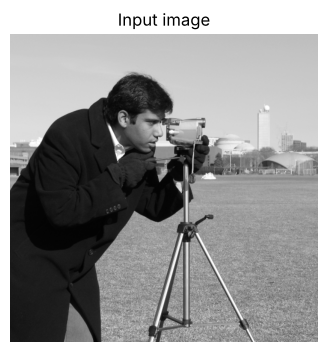

In [2]:
IMAGE_PATH = None

def load_gray(path=None):
    # Returns a grayscale image as floats in the range [0, 1]
    if path is None:
        return img_as_float(data.camera())
    img = io.imread(path)
    if img.ndim == 3:
        if img.shape[2] == 4:      # drop the alpha channel
            img = img[:, :, :3]
        img = color.rgb2gray(img)
    return img_as_float(img)

image = load_gray(IMAGE_PATH)
print("Image shape:", image.shape)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Input image")
plt.axis("off")
plt.show()

---
# Part 1: Local Binary Pattern

For each pixel, compare its 8 neighbours with the centre pixel $g_c$:

$$LBP = \sum_{p=0}^{7} s(g_p - g_c)\,2^p, \qquad s(x)=\begin{cases}1 & x \ge 0\\ 0 & x<0\end{cases}$$

This gives an 8-bit code from 0 to 255 that describes the local texture. The histogram of these codes is commonly used as a texture feature.

Neighbours are read clockwise, starting from the top-left pixel. Border pixels do not have 8 neighbours, so they are left out and the output is 2 pixels smaller in each dimension.

In [3]:
def lbp(img):
    # Local Binary Pattern with 8 neighbours and radius 1
    center = img[1:-1, 1:-1]

    # (row, column) offsets, clockwise from the top-left neighbour
    offsets = [(-1, -1), (-1, 0), (-1, 1), (0, 1),
               (1, 1), (1, 0), (1, -1), (0, -1)]

    result = np.zeros(center.shape, dtype=np.uint8)
    h, w = img.shape

    for bit, (dr, dc) in enumerate(offsets):
        neighbour = img[1 + dr : h - 1 + dr, 1 + dc : w - 1 + dc]
        result |= (neighbour >= center).astype(np.uint8) << bit

    return result

### Check with a small example

In [4]:
example = np.array([[6, 5, 2],
                    [7, 6, 1],
                    [9, 8, 7]], dtype=float)

code_value = lbp(example)[0, 0]

# Clockwise from top-left: 6, 5, 2, 1, 7, 8, 9, 7
# Compared with centre 6:  1, 0, 0, 0, 1, 1, 1, 1
# Bit 0 is the first neighbour, so the bits are read from right to left
print("LBP code:", code_value)
print("Binary  :", format(code_value, "08b"))

LBP code: 241
Binary  : 11110001


### LBP result and histogram

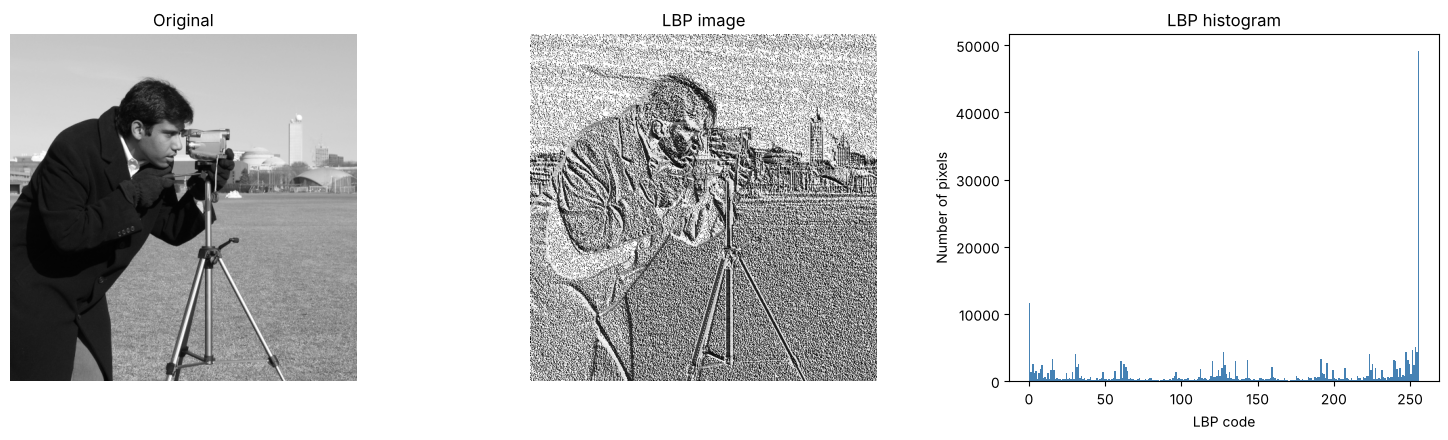

In [5]:
lbp_image = lbp(image)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

ax[0].imshow(image, cmap="gray")
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(lbp_image, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("LBP image")
ax[1].axis("off")

ax[2].hist(lbp_image.ravel(), bins=256, range=(0, 256), color="steelblue")
ax[2].set_title("LBP histogram")
ax[2].set_xlabel("LBP code")
ax[2].set_ylabel("Number of pixels")

plt.tight_layout()
plt.show()

---
# Part 2: Image Denoising

## Adding noise

- **Gaussian noise (additive):** $g = f + n$, where $n \sim \mathcal{N}(0, \sigma^2)$
- **Speckle noise (multiplicative):** $g = f + f\,n$, where $n \sim \mathcal{N}(0, \sigma^2)$

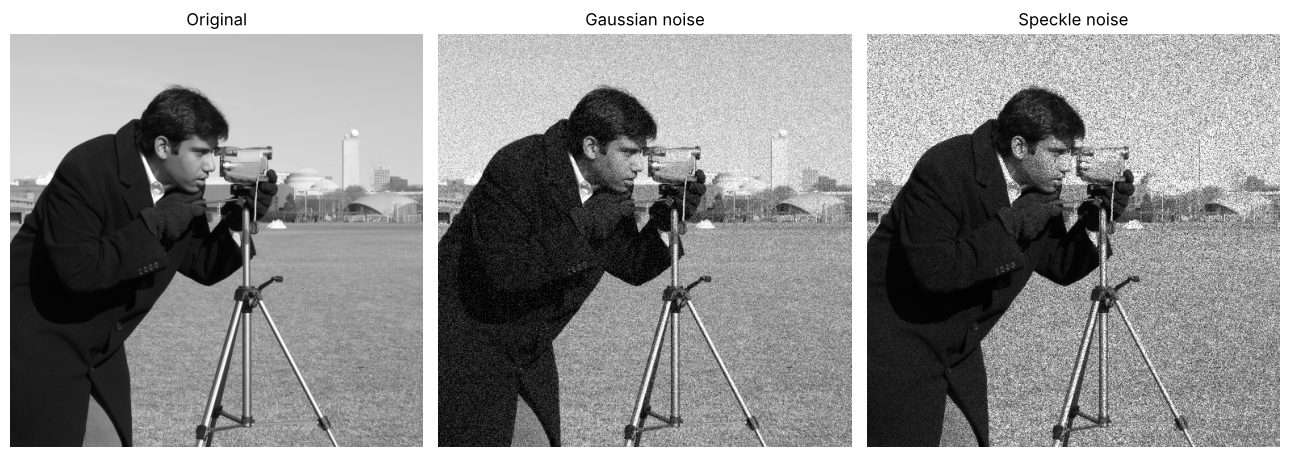

In [6]:
rng = np.random.default_rng(42)   # fixed seed so the results can be repeated

def add_gaussian_noise(img, sigma=20/255):
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 1)

def add_speckle_noise(img, sigma=0.25):
    return np.clip(img + img * rng.normal(0, sigma, img.shape), 0, 1)

gaussian_noisy = add_gaussian_noise(image)
speckle_noisy = add_speckle_noise(image)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, img, title in zip(ax, [image, gaussian_noisy, speckle_noisy],
                         ["Original", "Gaussian noise", "Speckle noise"]):
    a.imshow(img, cmap="gray", vmin=0, vmax=1)
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()

## Filters

Every filter uses a `k x k` window around each pixel. The image is padded by reflection so that the output has the same size as the input.

**(a) Wiener filter:** adapts to the local mean $\mu$ and variance $\sigma_L^2$, smoothing flat regions more than edges. The noise variance $\nu^2$ is estimated as the average local variance.

$$\hat f = \mu + \frac{\max(\sigma_L^2-\nu^2,\,0)}{\max(\sigma_L^2,\,\nu^2)}\,(g-\mu)$$

**(b) Median filter:** replaces each pixel with the median of its window.

**(c) Gaussian filter:** takes a weighted average, with weights that decrease with distance from the centre.

$$G(x,y)=\frac{1}{W}\exp\left(-\frac{x^2+y^2}{2\sigma_s^2}\right)$$

**(d) Bilateral filter:** multiplies the Gaussian spatial weight by a range weight, so pixels with very different intensities contribute little and edges are preserved.

$$w = \exp\left(-\frac{x^2+y^2}{2\sigma_s^2}\right)\exp\left(-\frac{(I_{neighbour}-I_{centre})^2}{2\sigma_r^2}\right)$$

In [7]:
def get_windows(img, k):
    # Returns an array of shape (H, W, k, k) holding the window around each pixel
    pad = k // 2
    padded = np.pad(img, pad, mode="reflect")
    return sliding_window_view(padded, (k, k))

def default_sigma(k):
    # Common rule for choosing sigma from the window size (0.8 for 3x3, 1.1 for 5x5)
    return 0.3 * ((k - 1) * 0.5 - 1) + 0.8

def gaussian_kernel(k, sigma):
    ax = np.arange(k) - k // 2
    x, y = np.meshgrid(ax, ax)
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum()


def wiener_filter(img, k=3):
    win = get_windows(img, k)
    local_mean = win.mean(axis=(2, 3))
    local_var = win.var(axis=(2, 3))
    noise_var = local_var.mean()

    gain = np.maximum(local_var - noise_var, 0) / np.maximum(local_var, noise_var)
    return local_mean + gain * (img - local_mean)


def median_filter(img, k=3):
    return np.median(get_windows(img, k), axis=(2, 3))


def gaussian_filter(img, k=3, sigma=None):
    sigma = default_sigma(k) if sigma is None else sigma
    kernel = gaussian_kernel(k, sigma)
    return np.sum(get_windows(img, k) * kernel, axis=(2, 3))


def bilateral_filter(img, k=3, sigma_s=None, sigma_r=0.2):
    sigma_s = default_sigma(k) if sigma_s is None else sigma_s
    spatial = gaussian_kernel(k, sigma_s)
    win = get_windows(img, k)

    difference = win - img[:, :, None, None]
    weights = spatial * np.exp(-difference**2 / (2 * sigma_r**2))
    return np.sum(weights * win, axis=(2, 3)) / np.sum(weights, axis=(2, 3))


filters = {
    "Wiener": wiener_filter,
    "Median": median_filter,
    "Gaussian": gaussian_filter,
    "Bilateral": bilateral_filter,
}
window_sizes = [3, 5]

## Apply every filter to both noisy images

In [8]:
noisy_images = {"Gaussian noise": gaussian_noisy, "Speckle noise": speckle_noisy}

outputs = {}
rows = []

for noise_name, noisy in noisy_images.items():
    rows.append({"Noise": noise_name, "Filter": "No filter (noisy input)", "Window": "-",
                 "PSNR (dB)": psnr(image, noisy, data_range=1),
                 "SSIM": ssim(image, noisy, data_range=1)})

    for filter_name, filter_function in filters.items():
        for k in window_sizes:
            result = np.clip(filter_function(noisy, k), 0, 1)
            outputs[(noise_name, filter_name, k)] = result
            rows.append({"Noise": noise_name, "Filter": filter_name, "Window": f"{k}x{k}",
                         "PSNR (dB)": psnr(image, result, data_range=1),
                         "SSIM": ssim(image, result, data_range=1)})

results = pd.DataFrame(rows)
print("Done")

Done


## Visual results

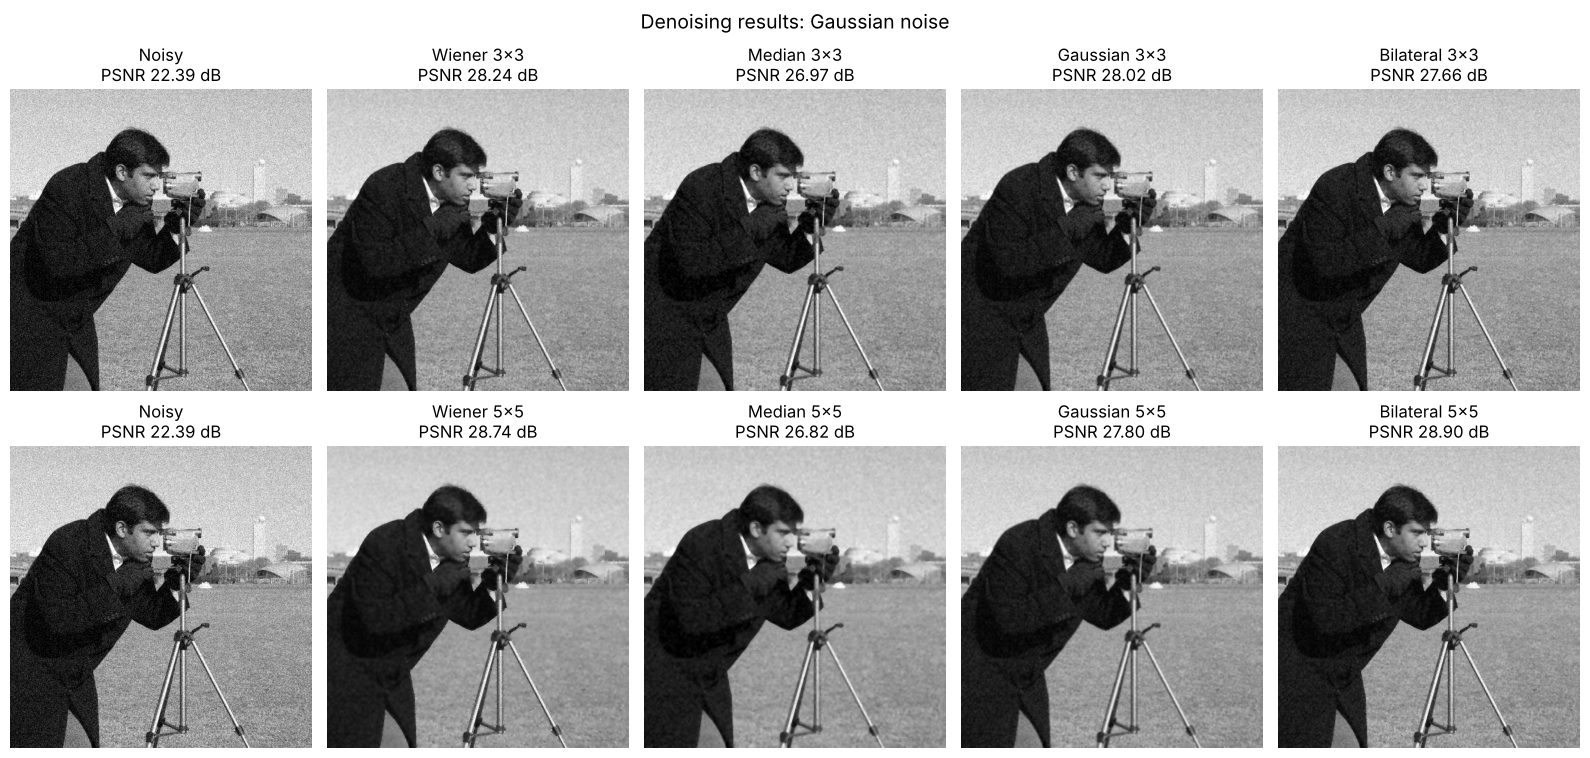

In [9]:
def show_results(noise_name):
    noisy = noisy_images[noise_name]
    n_cols = len(filters) + 1
    fig, ax = plt.subplots(len(window_sizes), n_cols, figsize=(3.2 * n_cols, 8))

    for r, k in enumerate(window_sizes):
        ax[r, 0].imshow(noisy, cmap="gray", vmin=0, vmax=1)
        ax[r, 0].set_title(f"Noisy\nPSNR {psnr(image, noisy, data_range=1):.2f} dB")
        ax[r, 0].axis("off")

        for c, filter_name in enumerate(filters, start=1):
            out = outputs[(noise_name, filter_name, k)]
            ax[r, c].imshow(out, cmap="gray", vmin=0, vmax=1)
            ax[r, c].set_title(f"{filter_name} {k}x{k}\nPSNR {psnr(image, out, data_range=1):.2f} dB")
            ax[r, c].axis("off")

    fig.suptitle(f"Denoising results: {noise_name}", fontsize=14)
    plt.tight_layout()
    plt.show()

show_results("Gaussian noise")

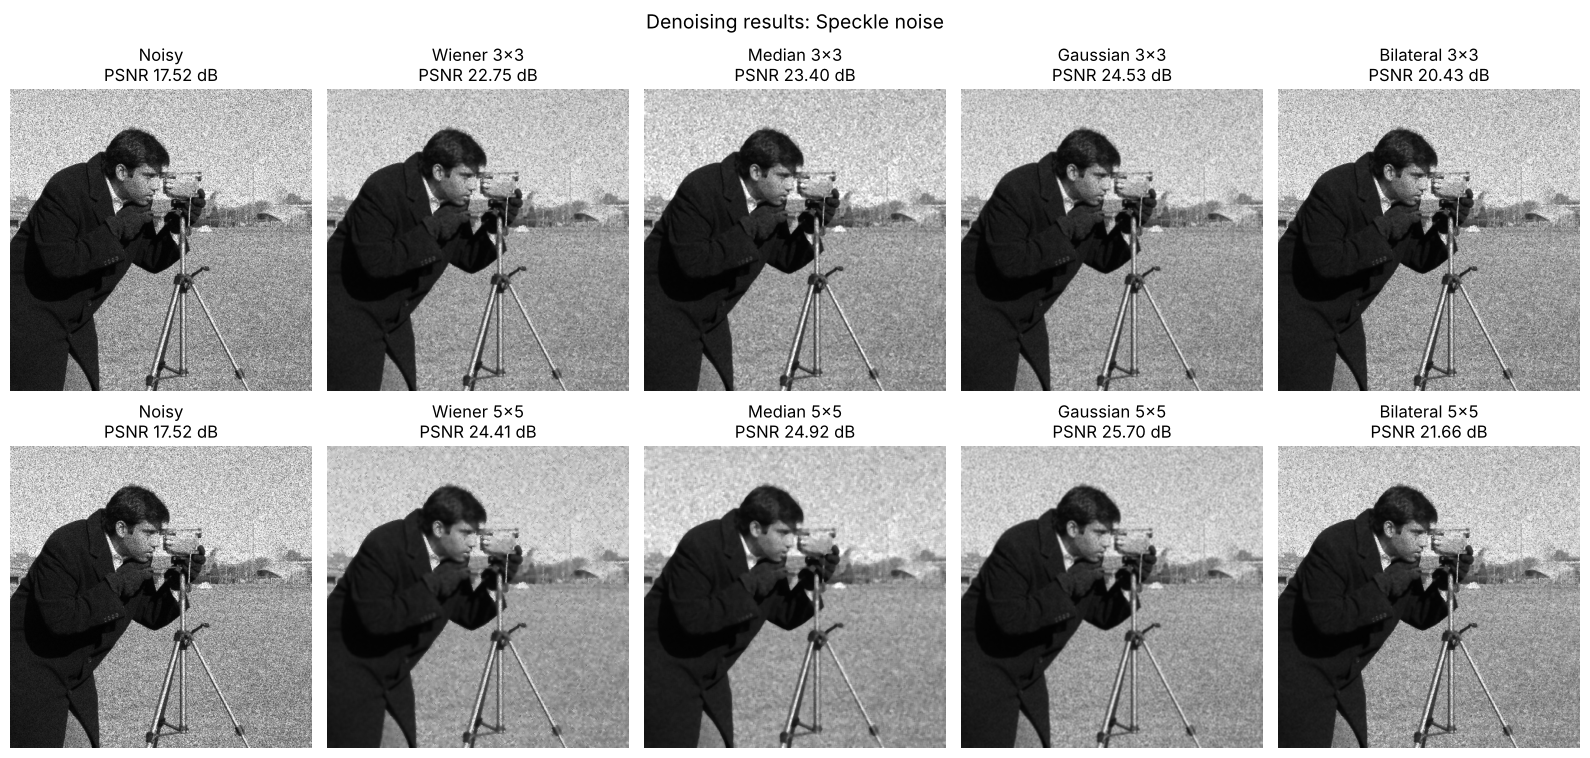

In [10]:
show_results("Speckle noise")

## Quantitative comparison

Higher PSNR and SSIM indicate that the filtered image is closer to the original.

In [11]:
results.round(4)

,Noise,Filter,Window,PSNR (dB),SSIM
0,Gaussian noise,No filter (noisy input),-,22.3948,0.3679
1,Gaussian noise,Wiener,3x3,28.2402,0.6581
2,Gaussian noise,Wiener,5x5,28.7411,0.7397
3,Gaussian noise,Median,3x3,26.9726,0.5765
4,Gaussian noise,Median,5x5,26.8182,0.6603
5,Gaussian noise,Gaussian,3x3,28.0164,0.6411
6,Gaussian noise,Gaussian,5x5,27.7977,0.7054
7,Gaussian noise,Bilateral,3x3,27.6615,0.5995
8,Gaussian noise,Bilateral,5x5,28.8955,0.6876
9,Speckle noise,No filter (noisy input),-,17.5213,0.3665


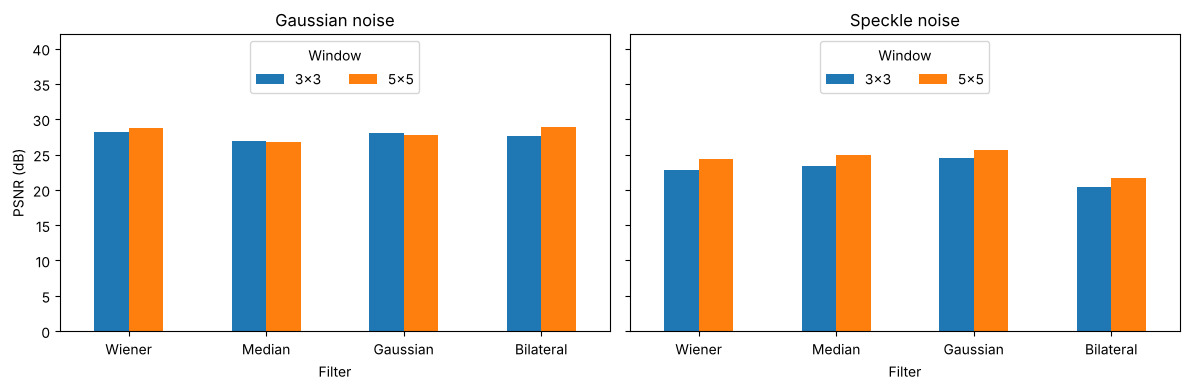

Best filter for each noise type (by PSNR):
         Noise    Filter Window  PSNR (dB)   SSIM
Gaussian noise Bilateral    5x5    28.8955 0.6876
 Speckle noise  Gaussian    5x5    25.7017 0.6124


In [12]:
filtered = results[results["Filter"] != "No filter (noisy input)"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, noise_name in zip(ax, noisy_images):
    subset = filtered[filtered["Noise"] == noise_name]
    table = subset.pivot(index="Filter", columns="Window", values="PSNR (dB)").loc[list(filters)]
    table.plot(kind="bar", ax=a, rot=0)
    a.set_title(noise_name)
    a.set_ylabel("PSNR (dB)")
    a.set_ylim(0, 42)
    a.legend(title="Window", loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

print("Best filter for each noise type (by PSNR):")
best = filtered.loc[filtered.groupby("Noise")["PSNR (dB)"].idxmax()]
print(best[["Noise", "Filter", "Window", "PSNR (dB)", "SSIM"]].round(4).to_string(index=False))

## Conclusion

- **LBP** encodes local texture as an 8-bit code. It depends only on whether neighbours are brighter or darker than the centre, so it is unaffected by uniform brightness changes.
- **Wiener** adapts to local variance, smoothing flat areas more strongly than detailed ones.
- **Median** is a non-linear filter that preserves edges fairly well, and it is especially effective against outliers.
- **Gaussian** reduces noise well but also blurs edges, particularly with larger windows.
- **Bilateral** preserves edges better than Gaussian filtering because it also considers intensity differences.
- **Window size:** a 5x5 window removes more noise than 3x3 but can lose more fine detail.

The table and chart above show which filter scored best for each noise type. These rankings can change with the image, the noise level and the filter parameters.